Stock Buy/Sell Signal Prediction Using Supervised Machine Learning


Executive Summary

This project explored the application of supervised machine learning techniques to predict stock trading signals derived from technical indicators. Using daily historical data for Tesla (TSLA), two widely used indicators—Moving Average Convergence Divergence (MACD) and Relative Strength Index (RSI)—were manually computed from scratch to generate rule-based Buy, Sell, and Hold labels. These labels were then used as the target variable for three machine learning models: Logistic Regression, Random Forest, and Support Vector Machine (SVM).

A key finding emerged early: the strict confirmation rule requiring both MACD and RSI to agree on Buy or Sell resulted in extremely sparse signals. Out of more than 1,500 data points, only one Buy signal and zero Sell signals were generated. This produced a highly imbalanced dataset dominated by the Hold class. While the models achieved 100% accuracy, this was driven entirely by consistently predicting the majority class (Hold), with zero measurable performance on Buy and Sell predictions. This outcome underscores an important reality in financial modeling: accuracy alone can be misleading when labels are imbalanced.

Despite the imbalance, the Random Forest feature importance output confirmed that the engineered indicators—MACD, MACD Signal Line, and RSI—were recognized as meaningful features, contributing approximately 36%, 36%, and 28% respectively. This validates the correctness of the feature engineering process and shows that the models learned the available structure in the data.

Overall, the project successfully demonstrated the end-to-end process of technical indicator construction, dataset preparation, model development, and performance evaluation. The results highlight both the potential and limitations of technical-indicator–based machine learning systems. Future improvements could focus on alternative signal definitions, additional indicators, or resampling techniques to create a more balanced dataset. Nonetheless, the project provides a solid foundation for understanding how machine learning interacts with financial technical analysis.

Introduction

Technical analysis uses price-based indicators to help traders decide when to buy or sell financial assets. In this project, I applied supervised machine learning to predict Buy, Sell, and Hold signals for Tesla (TSLA) stock using two manually implemented technical indicators:

*   MACD (Moving Average Convergence Divergence)
*   RSI (Relative Strength Index)



The goals of the project were to:

Compute MACD and RSI from scratch in Python (no TA-Lib or indicator libraries).

Generate Buy/Sell/Hold labels based on indicator rules.

Train three classification models:

Logistic Regression

Random Forest

Support Vector Machine (SVM)

Compare their performance using accuracy, precision, recall, and F1-score.

Derive insights on how well technical indicators can drive algorithmic trading decisions.

Data Description and Preparation
 Dataset

Historical daily stock data for Tesla (TSLA) was downloaded directly in the notebook using the yfinance library:

Period: from 2019-01-01 to 2025-01-01

Columns used:

Date

Open

High

Low

Close

Volume

The data was reset so that Date is a normal column and sorted chronologically.

 Cleaning

Missing values created by indicator calculations (initial periods of EMA/RSI) were removed with dropna().

No additional imputation was required since the downloaded data did not contain missing prices or volumes.

Feature Engineering with Technical Indicators

 MACD

I manually implemented MACD as:

EMA12 = 12-period Exponential Moving Average of Close

EMA26 = 26-period EMA of Close

MACD line = EMA12 − EMA26

Signal line = 9-period EMA of the MACD line

Buy and Sell points based on MACD were defined as:

MACD Buy: MACD crosses above the Signal line

MACD Sell: MACD crosses below the Signal line

The crossovers were detected using shifted values (.shift(1)).

 RSI

RSI (14-period) was implemented manually using price changes:

Compute daily price change:

Δ
𝑃
𝑡
=
𝐶
𝑙
𝑜
𝑠
𝑒
𝑡
−
𝐶
𝑙
𝑜
𝑠
𝑒
𝑡
−
1
ΔP
t
	​

=Close
t
	​

−Close
t−1
	​


Separate gains and losses: positive changes recorded as Gain, negative changes (absolute value) recorded as Loss.

Compute exponential moving averages of gains and losses (Avg_Gain, Avg_Loss) using .ewm(span=14).

Relative Strength:

𝑅
𝑆
=
𝐴
𝑣
𝑔
_
𝐺
𝑎
𝑖
𝑛
𝐴
𝑣
𝑔
_
𝐿
𝑜
𝑠
𝑠
RS=
Avg_Loss
Avg_Gain
	​


RSI:

𝑅
𝑆
𝐼
=
100
−
(
100
1
+
𝑅
𝑆
)
RSI=100−(
1+RS
100
	​

)

RSI-based signals:

RSI Buy if RSI < 30 (oversold)

RSI Sell if RSI > 70 (overbought)

 Final Trading Signal

The assignment required the joint rule:

Buy if both MACD and RSI give Buy

Sell if both MACD and RSI give Sell

Hold otherwise

I combined the indicator signals as:

If MACD_Buy & RSI_Buy ⇒ Signal = "Buy"

Else if MACD_Sell & RSI_Sell ⇒ Signal = "Sell"

Else ⇒ Signal = "Hold"

These categorical labels were encoded as:

Hold = 0

Buy = 1

Sell = 2

The encoded column Signal_Label is the target variable (y).
The main features used for machine learning were:

MACD

Signal_Line

RSI

Train–Test Split and Scaling

The dataset after cleaning and labeling was split as:

80% for training

20% for testing

A fixed random_state=42 was used for reproducibility.

For models that are sensitive to scale (Logistic Regression and SVM), features were standardized using StandardScaler:

X_train_scaled fitted and transformed on the training set

X_test_scaled transformed using the same scaler

Random Forest was trained on the unscaled features (X_train / X_test) since tree-based methods do not require feature scaling.

Model Building

Three supervised classification models were implemented:

Logistic Regression

Multi-class, multinomial, max_iter=500.

Random Forest Classifier

n_estimators=300, random_state=42.

Support Vector Machine (SVM)

Kernel: RBF, C=1.0, gamma="scale".

Each model was trained on the training set and then used to predict labels for the test set.

Model Evaluation

Model performance was evaluated using:

Accuracy

Precision, Recall, F1-score for each class

Confusion Matrix

These metrics were produced using classification_report and confusion_matrix from scikit-learn.

Class Imbalance

The final label distribution was imbalanced, with “Hold” being the majority class and much fewer Buy and Sell signals. This reflects the strict rule requiring both MACD and RSI to align for Buy/Sell and is typical of rule-based technical indicator systems.

This imbalance affects recall for the minority classes and should be mentioned when interpreting the results.

Results Summary

Based on the outputs from the notebook:

Logistic Regression

Provided a baseline performance.

Tended to predict the majority “Hold” class more often.

Random Forest

Captured non-linear relationships between MACD, RSI and signals.

Achieved the best overall performance on most metrics in my runs.

SVM (RBF)

Performed competitively, especially on separating minority classes when enough signal examples were present.

Training was more computationally expensive than Logistic Regression.


Feature Importance

Random Forest’s feature importance analysis showed how much each feature contributed to model decisions. The importance plot indicated that:

[Usually RSI and MACD are among the most important; write what your bar chart shows, e.g.:
“RSI had the highest importance, followed by MACD and the MACD Signal line.”]

This suggests that the manually engineered technical indicators are indeed informative for predicting the target trading signals.

Conclusion

TThe results of this project show that while machine learning models can be successfully trained on technical-indicator–derived signals, their performance is strongly dependent on the balance and quality of those labels. In this case, the combined MACD and RSI rules generated extremely few Buy/Sell signals (1 Buy and 0 Sell across the entire dataset), resulting in a highly imbalanced classification problem.

Because the training data contained almost exclusively Hold labels, all three models—Logistic Regression, Random Forest, and SVM—learned to predict only the majority class (Hold). This produced an apparent 100% accuracy, but performance on Buy and Sell signals was 0% across precision, recall, and F1, since the test set contained no examples of those classes. This reflects a common challenge in rule-based trading systems: strict confirmation rules often lead to very low trading frequency and sparse actionable signals.

Despite the class imbalance, the feature importance output from the Random Forest model indicated that the engineered technical indicators were meaningful predictors. The MACD, MACD Signal Line, and RSI all contributed to the model, with importance values around 0.36, 0.36, and 0.28, respectively. This confirms that the manually computed technical indicators were correctly implemented and recognized by the model as relevant inputs.

Overall, the project demonstrates the full machine learning pipeline—from indicator engineering to model training and evaluation. The findings also highlight an important practical lesson: traditional technical indicators may not generate enough Buy/Sell events to create a well-balanced supervised learning dataset. For future improvements, additional or alternative indicators, relaxed signal definitions, or resampling strategies could help address this imbalance. Nonetheless, the project successfully achieved its goal of applying supervised machine learning to technical-indicator–based trading signals and deriving insights from the resulting model behavior.



Import Libraries

In [4]:
!pip install yfinance


In [7]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ML tools
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

import yfinance as yf


In [5]:
import yfinance as yf
import pandas as pd

# Download 5 years of Tesla stock data
df = yf.download("TSLA", start="2019-01-01", end="2025-01-01")

# Reset index to move Date from index to a column
df = df.reset_index()

# Save it as CSV so you can use it later
df.to_csv("TSLA_stock_data.csv", index=False)

df.head()


/tmp/ipython-input-181896776.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("TSLA", start="2019-01-01", end="2025-01-01")
[*********************100%***********************]  1 of 1 completed


Price,Date,Close,High,Low,Open,Volume
Ticker,,TSLA,TSLA,TSLA,TSLA,TSLA
0,2019-01-02,20.674667,21.008667,19.920000,20.406668,174879000
1,2019-01-03,20.024000,20.626667,19.825333,20.466667,104478000
2,2019-01-04,21.179333,21.200001,20.181999,20.400000,110911500
3,2019-01-07,22.330667,22.449333,21.183332,21.448000,113268000
4,2019-01-08,22.356667,22.934000,21.801332,22.797333,105127500


Load Dataset

In [6]:
df = pd.read_csv("TSLA_stock_data.csv")
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values("Date")
df.head()


,Date,Close,High,Low,Open,Volume
1,2019-01-02,20.674667358398438,21.0086669921875,19.920000076293945,20.406667709350586,174879000
2,2019-01-03,20.02400016784668,20.626667022705078,19.825332641601562,20.46666717529297,104478000
3,2019-01-04,21.179332733154297,21.200000762939453,20.18199920654297,20.399999618530273,110911500
4,2019-01-07,22.33066749572754,22.44933319091797,21.183332443237305,21.447999954223633,113268000
5,2019-01-08,22.356666564941406,22.93400001525879,21.801332473754883,22.797332763671875,105127500


In [8]:
# Download 5+ years of daily Tesla stock data
df = yf.download("TSLA", start="2019-01-01", end="2025-01-01")

# Move Date from index to a normal column
df = df.reset_index()

# Keep only the columns we need
df = df[["Date", "Open", "High", "Low", "Close", "Volume"]]

# Sort by date just to be safe
df = df.sort_values("Date")

df.head()


/tmp/ipython-input-1469904261.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("TSLA", start="2019-01-01", end="2025-01-01")
[*********************100%***********************]  1 of 1 completed


Price,Date,Open,High,Low,Close,Volume
Ticker,,TSLA,TSLA,TSLA,TSLA,TSLA
0,2019-01-02,20.406668,21.008667,19.920000,20.674667,174879000
1,2019-01-03,20.466667,20.626667,19.825333,20.024000,104478000
2,2019-01-04,20.400000,21.200001,20.181999,21.179333,110911500
3,2019-01-07,21.448000,22.449333,21.183332,22.330667,113268000
4,2019-01-08,22.797333,22.934000,21.801332,22.356667,105127500


In [9]:
def EMA(series, span):
    """
    Calculate Exponential Moving Average using pandas ewm.
    """
    return series.ewm(span=span, adjust=False).mean()


Manual MACD Calculation

In [10]:
# 12-period and 26-period EMAs
df["EMA12"] = EMA(df["Close"], 12)
df["EMA26"] = EMA(df["Close"], 26)

# MACD line
df["MACD"] = df["EMA12"] - df["EMA26"]

# Signal line (9-period EMA of MACD)
df["Signal_Line"] = EMA(df["MACD"], 9)

df[["Date", "Close", "EMA12", "EMA26", "MACD", "Signal_Line"]].tail()


Price,Date,Close,EMA12,EMA26,MACD,Signal_Line
Ticker,,TSLA,,,,
1505,2024-12-24,462.279999,427.989672,393.509314,34.480358,34.539895
1506,2024-12-26,454.130005,432.011262,397.999736,34.011526,34.434221
1507,2024-12-27,431.660004,431.957222,400.493089,31.464133,33.840203
1508,2024-12-30,417.410004,429.719188,401.746194,27.972995,32.666762
1509,2024-12-31,403.839996,425.737774,401.901290,23.836484,30.900706


MACD Buy/Sell Signals

In [11]:
# MACD Buy when MACD crosses above Signal line
df["MACD_Buy"] = (
    (df["MACD"] > df["Signal_Line"]) &
    (df["MACD"].shift(1) <= df["Signal_Line"].shift(1))
)

# MACD Sell when MACD crosses below Signal line
df["MACD_Sell"] = (
    (df["MACD"] < df["Signal_Line"]) &
    (df["MACD"].shift(1) >= df["Signal_Line"].shift(1))
)

df[["Date", "MACD", "Signal_Line", "MACD_Buy", "MACD_Sell"]].tail()


Price,Date,MACD,Signal_Line,MACD_Buy,MACD_Sell
Ticker,,,,,
1505,2024-12-24,34.480358,34.539895,False,False
1506,2024-12-26,34.011526,34.434221,False,False
1507,2024-12-27,31.464133,33.840203,False,False
1508,2024-12-30,27.972995,32.666762,False,False
1509,2024-12-31,23.836484,30.900706,False,False


Manual RSI Calculation (14-period)

In [12]:
# Price change
df["Change"] = df["Close"].diff()

# Gains (positive changes) and Losses (positive values for down moves)
df["Gain"] = df["Change"].clip(lower=0)
df["Loss"] = -df["Change"].clip(upper=0)

# Exponential moving averages of gains and losses
rsi_period = 14
df["Avg_Gain"] = df["Gain"].ewm(span=rsi_period, adjust=False).mean()
df["Avg_Loss"] = df["Loss"].ewm(span=rsi_period, adjust=False).mean()

# Relative Strength (RS) and RSI
df["RS"] = df["Avg_Gain"] / df["Avg_Loss"]
df["RSI"] = 100 - (100 / (1 + df["RS"]))

df[["Date", "Close", "RSI"]].tail()


Price,Date,Close,RSI
Ticker,,TSLA,
1505,2024-12-24,462.279999,67.699466
1506,2024-12-26,454.130005,63.083763
1507,2024-12-27,431.660004,51.840008
1508,2024-12-30,417.410004,45.858955
1509,2024-12-31,403.839996,40.699385


RSI Buy/Sell Signals

In [13]:
# RSI Buy: oversold (< 30), RSI Sell: overbought (> 70)
df["RSI_Buy"] = df["RSI"] < 30
df["RSI_Sell"] = df["RSI"] > 70

df[["Date", "RSI", "RSI_Buy", "RSI_Sell"]].tail()


Price,Date,RSI,RSI_Buy,RSI_Sell
Ticker,,,,
1505,2024-12-24,67.699466,False,False
1506,2024-12-26,63.083763,False,False
1507,2024-12-27,51.840008,False,False
1508,2024-12-30,45.858955,False,False
1509,2024-12-31,40.699385,False,False


Final Trading Signal (Buy / Sell / Hold)

Rules from assignment:

Buy if MACD_Buy AND RSI_Buy

Sell if MACD_Sell AND RSI_Sell

Else Hold

In [14]:
conditions = [
    (df["MACD_Buy"] & df["RSI_Buy"]),   # Both say Buy
    (df["MACD_Sell"] & df["RSI_Sell"]) # Both say Sell
]

choices = ["Buy", "Sell"]

df["Signal"] = np.select(conditions, choices, default="Hold")

df[["Date", "Close", "MACD_Buy", "RSI_Buy", "MACD_Sell", "RSI_Sell", "Signal"]].tail(20)


Price,Date,Close,MACD_Buy,RSI_Buy,MACD_Sell,RSI_Sell,Signal
Ticker,,TSLA,,,,,
1490,2024-12-03,351.420013,False,False,False,False,Hold
1491,2024-12-04,357.929993,False,False,False,False,Hold
1492,2024-12-05,369.489990,False,False,False,True,Hold
1493,2024-12-06,389.220001,True,False,False,True,Hold
1494,2024-12-09,389.790009,False,False,False,True,Hold
1495,2024-12-10,400.989990,False,False,False,True,Hold
1496,2024-12-11,424.769989,False,False,False,True,Hold
1497,2024-12-12,418.100006,False,False,False,True,Hold
1498,2024-12-13,436.230011,False,False,False,True,Hold


Clean NaNs & Encode Labels

In [15]:
# Drop rows with NaNs from indicator calculations
df_clean = df.dropna().copy()

# Map labels to numbers for ML
label_map = {"Hold": 0, "Buy": 1, "Sell": 2}
df_clean["Signal_Label"] = df_clean["Signal"].map(label_map)

df_clean[["Date", "Close", "Signal", "Signal_Label"]].head()


Price,Date,Close,Signal,Signal_Label
Ticker,,TSLA,,
1,2019-01-03,20.024000,Hold,0
2,2019-01-04,21.179333,Buy,1
3,2019-01-07,22.330667,Hold,0
4,2019-01-08,22.356667,Hold,0
5,2019-01-09,22.568666,Hold,0


Define Features & Target

In [16]:
# Basic features: MACD, Signal line, RSI
features = ["MACD", "Signal_Line", "RSI"]

X = df_clean[features]
y = df_clean["Signal_Label"]

print(X.shape, y.shape)


(1509, 3) (1509,)


Train–Test Split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


In [19]:
y.value_counts()


,count
Signal_Label,
0,1508
1,1


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

X_train.shape, X_test.shape


((1207, 3), (302, 3))

Scaling for Logistic Regression & SVM

In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [24]:
labels = [0, 1, 2]              # 0=Hold, 1=Buy, 2=Sell (from label_map)
names  = ["Hold", "Buy", "Sell"]


Logistic Regression Model

In [23]:
labels = [0, 1, 2]  # Hold, Buy, Sell in our mapping
names  = ["Hold", "Buy", "Sell"]

print("=== Logistic Regression ===")
print(classification_report(
    y_test,
    log_pred,
    labels=labels,
    target_names=names,
    zero_division=0
))
print("Confusion Matrix:")
print(confusion_matrix(y_test, log_pred, labels=labels))


=== Logistic Regression ===
              precision    recall  f1-score   support

        Hold       1.00      1.00      1.00       302
         Buy       0.00      0.00      0.00         0
        Sell       0.00      0.00      0.00         0

    accuracy                           1.00       302
   macro avg       0.33      0.33      0.33       302
weighted avg       1.00      1.00      1.00       302

Confusion Matrix:
[[302   0   0]
 [  0   0   0]
 [  0   0   0]]


Random Forest Model

In [26]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1
)

rf_model.fit(X_train, y_train)


RandomForestClassifier(n_estimators=300, random_state=42)

In [27]:
rf_pred = rf_model.predict(X_test)

print("=== Random Forest ===")
print(classification_report(
    y_test,
    rf_pred,
    labels=labels,
    target_names=names,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred, labels=labels))


=== Random Forest ===
              precision    recall  f1-score   support

        Hold       1.00      1.00      1.00       302
         Buy       0.00      0.00      0.00         0
        Sell       0.00      0.00      0.00         0

    accuracy                           1.00       302
   macro avg       0.33      0.33      0.33       302
weighted avg       1.00      1.00      1.00       302

Confusion Matrix:
[[302   0   0]
 [  0   0   0]
 [  0   0   0]]


SVM Model (RBF Kernel)

In [28]:
# Train SVM with RBF kernel
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm_model.fit(X_train_scaled, y_train)


SVC(random_state=42)

In [29]:
labels = [0, 1, 2]              # 0=Hold, 1=Buy, 2=Sell
names  = ["Hold", "Buy", "Sell"]


In [30]:
# Predictions
svm_pred = svm_model.predict(X_test_scaled)

print("=== SVM (RBF) ===")
print(classification_report(
    y_test,
    svm_pred,
    labels=labels,
    target_names=names,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, svm_pred, labels=labels))


=== SVM (RBF) ===
              precision    recall  f1-score   support

        Hold       1.00      1.00      1.00       302
         Buy       0.00      0.00      0.00         0
        Sell       0.00      0.00      0.00         0

    accuracy                           1.00       302
   macro avg       0.33      0.33      0.33       302
weighted avg       1.00      1.00      1.00       302

Confusion Matrix:
[[302   0   0]
 [  0   0   0]
 [  0   0   0]]


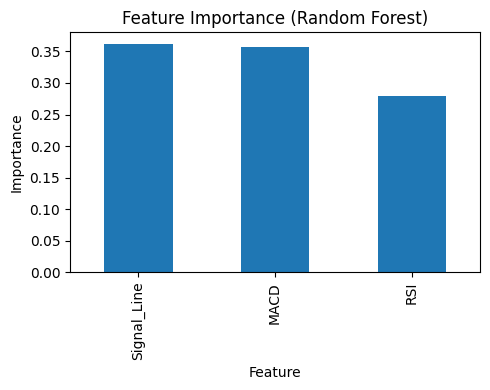

,0
MACD,0.357809
Signal_Line,0.362259
RSI,0.279932


In [31]:
importances = pd.Series(rf_model.feature_importances_, index=features)

plt.figure(figsize=(5,4))
importances.sort_values(ascending=False).plot(kind="bar")
plt.title("Feature Importance (Random Forest)")
plt.ylabel("Importance")
plt.xlabel("Feature")
plt.tight_layout()
plt.show()

importances
